# 정렬 입력 × 합성 비율 — 합성 효과가 정렬 입력에서도 유지되는가?

지금까지의 결과
- 기존 입력: 합성 0.25 가 합성 없음보다 Recall·위치 성능이 좋았다(F2 0.778 → 0.881).
- 정렬 입력(`align_0.4`) + 합성 0.25: 위치 성능·정상 오경보·Image AUROC 가 크게 좋아졌다.
- **빠진 것**: 정렬 입력에서 합성이 기여하는지(합성 0.0 과 비교)와 최적 비율. 이 노트북이 그 실험이다.

**실험**: 입력은 `align_0.4`(나사를 세워 128×384 로 입력)로 고정하고, 합성 비율 `0.0 / 0.25 / 0.5 / 1.0` × 시드 5개를 학습·평가한다.
그리고 같은 비율·같은 시드의 **기존 입력 결과**(`runs.csv`, `cam_methods.csv`)와 짝지어 비교한다.

통제 조건(기존 실험과 동일): train/val 분할(seed 42), 합성 풀(소스·대상은 train 안), ResNet-18, Adam 1e-4, weight 2.0, 40 epoch, val F2 최고 epoch 선택, patience 10.
평가는 합성 0장의 real test 55장(결함 19장은 위치 평가). 이미 돌린 `align_0.4 @ 0.25` 결과(`align_runs.csv`)는 같은 설정이라 재사용한다.

선행 파일: `splits/synthetic_split.csv` + `outputs/synthetic/`(합성 풀, 유형당 52장 이상), `runs.csv`, `cam_methods.csv`, `align_runs.csv`.
커널은 `screw_defect`.

In [1]:
import os, sys, time, copy
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() or not (ROOT / "splits").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("레포 루트를 찾지 못함")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import fbeta_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, LayerCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

from src.common.paths import SYNTHETIC_SPLIT_CSV, SYNTH_EXP_DIR
from src.common.utils import set_seed
from src.supervised.data import list_records
from src.supervised.dataset import val_transform
from src.supervised.model import build_model_bin
from src.supervised.loc_eval import load_mask, inv_normalize, _compute_pixel_metrics
from src.supervised import synth, align

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

W1105 12:48:47.707000 5244 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


device: cuda


## 1. 설정

In [2]:
QUICK = os.environ.get("SYNTH_QUICK") == "1"

SCALE = 0.4                                    # align_0.4 (입력 128x384)
RATIOS = [0.0, 0.25, 0.5, 1.0]
SEEDS = [0, 1, 2, 3, 4]
EPOCHS, PATIENCE, BAD_WEIGHT, BATCH, LR = 40, 10, 2.0, 16, 1e-4     # baseline 과 동일
SPLIT_SEED = 42
CAM_COMBOS = [("GradCAM", "layer4"), ("GradCAM", "layer3"), ("LayerCAM", "layer3"), ("GradCAM++", "layer3")]
METHODS = {"GradCAM": GradCAM, "GradCAM++": GradCAMPlusPlus, "LayerCAM": LayerCAM}

if QUICK:
    RATIOS, SEEDS, EPOCHS = [0.0, 0.5], [0], 3
TAG = "_quick" if QUICK else ""
RUNS_CSV = os.path.join(SYNTH_EXP_DIR, f"align_ratio_runs{TAG}.csv")
OLD_ALIGN_CSV = os.path.join(SYNTH_EXP_DIR, "align_runs.csv")          # 이미 돌린 align_0.4 @ 0.25
MODEL_DIR = os.path.join(SYNTH_EXP_DIR, f"models_align_ratio{TAG}")
os.makedirs(MODEL_DIR, exist_ok=True)
print("QUICK" if QUICK else "FULL", "| ratios", RATIOS, "| seeds", SEEDS, "| epochs", EPOCHS)

FULL | ratios [0.0, 0.25, 0.5, 1.0] | seeds [0, 1, 2, 3, 4] | epochs 40


## 2. 데이터 — 기존 실험과 같은 분할 · 같은 합성 풀

In [3]:
CLASS_NAMES = ["good", "type1", "type2", "type3", "type4", "type5"]
def collect(split):
    return [{"path": r["path"], "type": r["class"], "label": 0 if r["class"] == "good" else 1, "mask": r["mask"]}
            for r in list_records(split, CLASS_NAMES)]

real_train, test_recs = collect("train"), collect("test")
tr_idx, val_idx = train_test_split(np.arange(len(real_train)), test_size=0.2,
                                   stratify=[r["type"] for r in real_train], random_state=SPLIT_SEED)
tr_recs = [real_train[i] for i in tr_idx]; val_recs = [real_train[i] for i in val_idx]
P = lambda rs: {r["path"] for r in rs}
assert not (P(tr_recs) & P(val_recs)) and not (P(tr_recs) & P(test_recs)) and not (P(val_recs) & P(test_recs))

pool = synth.load_pool(SYNTHETIC_SPLIT_CSV)
assert pool is not None, "합성 풀이 없다 — 먼저 synthetic_resnet_experiment.ipynb 를 실행하세요"
n_normal = sum(r["type"] == "good" for r in tr_recs)
ALLOC = {r: synth.allocate(n_normal, r) for r in RATIOS}
PER_TYPE = max(max(a.values()) for a in ALLOC.values())
assert min(len(v) for v in pool.values()) >= PER_TYPE, f"합성 풀이 부족({PER_TYPE}장/유형 필요)"
src_all = {r["source"] for v in pool.values() for r in v}
assert src_all <= P(tr_recs), "합성 소스가 train 밖에서 왔다"

def train_set(ratio):
    s = synth.take(pool, ALLOC[ratio]) if ratio > 0 else []
    assert not (P(s) & (P(val_recs) | P(test_recs)))
    return tr_recs + s, len(s)

pd.DataFrame([{"비율": r, "정상": n_normal, "real 결함": len(tr_recs) - n_normal, "합성": sum(ALLOC[r].values()),
               "유형별": "/".join(str(ALLOC[r][t]) for t in synth.TYPES), "총 학습": len(tr_recs) + sum(ALLOC[r].values())}
              for r in RATIOS])

,비율,정상,real 결함,합성,유형별,총 학습
0,0.00,260,80,0,0/0/0/0/0,340
1,0.25,260,80,65,13/13/13/13/13,405
2,0.50,260,80,130,26/26/26/26/26,470
3,1.00,260,80,260,52/52/52/52/52,600


## 3. 정렬 입력 · 증강 · 학습/평가 함수

(`synthetic_align_experiment.ipynb` 와 동일) 정렬된 입력은 방향이 고정이므로 `RandomRotation(180)`·수직 반전은 쓰지 않고, 작은 회전·이동·배율 + 좌우 반전 + 밝기/대비를 쓴다.
위치 지표는 정렬 프레임 CAM 을 원본 프레임으로 역투영해 기존과 같은 224 프레임에서 계산한다.

In [4]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TRAIN_TF = transforms.Compose([
    transforms.RandomAffine(degrees=8, translate=(0.04, 0.03), scale=(0.9, 1.1), fill=200),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
EVAL_TF = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

_CACHE = {}
def aligned_pil(path):
    if path not in _CACHE:
        _CACHE[path] = Image.fromarray(align.align_scaled(path, SCALE))
    return _CACHE[path]

class AlignedDS(Dataset):
    def __init__(self, recs, tf): self.recs, self.tf = recs, tf
    def __len__(self): return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]
        return self.tf(aligned_pil(r["path"])), r["label"]

def loader(recs, train):
    return DataLoader(AlignedDS(recs, TRAIN_TF if train else EVAL_TF), batch_size=BATCH, shuffle=train, num_workers=0)

def train_one(ratio, seed):
    set_seed(seed)
    recs, n_syn = train_set(ratio)
    train_loader, val_loader = loader(recs, True), loader(val_recs, False)
    model = build_model_bin("resnet18").to(device)
    crit = nn.CrossEntropyLoss(weight=torch.tensor([1.0, BAD_WEIGHT]).to(device))
    opt = optim.Adam(model.parameters(), lr=LR)
    best_f2, best_ep, best_state, bad = 0.0, 0, copy.deepcopy(model.state_dict()), 0
    for ep in range(EPOCHS):
        model.train()
        for imgs, y in train_loader:
            opt.zero_grad(); crit(model(imgs.to(device)), y.to(device)).backward(); opt.step()
        model.eval(); yt, yp = [], []
        with torch.no_grad():
            for imgs, y in val_loader:
                yp.extend(model(imgs.to(device)).argmax(1).cpu().numpy()); yt.extend(y.numpy())
        f2 = fbeta_score(yt, yp, beta=2, pos_label=1, zero_division=0)
        if f2 > best_f2:
            best_f2, best_ep, best_state, bad = f2, ep + 1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
        if bad >= PATIENCE:
            break
    model.load_state_dict(best_state); model.eval()
    return model, best_f2, best_ep, len(recs), n_syn

defects = [r for r in test_recs if r["label"] == 1]
GT = np.stack([load_mask(r["mask"]) for r in defects])

def cam_maps(model, method, layer, recs):
    x = torch.stack([EVAL_TF(aligned_pil(r["path"])) for r in recs]).to(device)
    with METHODS[method](model=model, target_layers=[getattr(model, layer)[-1]]) as cam:
        cams = cam(input_tensor=x, targets=[ClassifierOutputTarget(1)] * len(x))
    return [align.cam_to_eval_frame(c, r["path"]) for c, r in zip(cams, recs)]       # 각 (224, 224)

def evaluate(model):
    yt, yp, pr = [], [], []
    with torch.no_grad():
        for imgs, y in loader(test_recs, False):
            lg = model(imgs.to(device))
            yp.extend(lg.argmax(1).cpu().numpy()); pr.extend(torch.softmax(lg, 1)[:, 1].cpu().numpy()); yt.extend(y.numpy())
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    out = dict(precision=precision_score(yt, yp, zero_division=0), recall=recall_score(yt, yp),
               f2=fbeta_score(yt, yp, beta=2, pos_label=1, zero_division=0), img_auroc=roc_auc_score(yt, pr),
               tn=tn, fp=fp, fn=fn, tp=tp)
    for m, l in CAM_COMBOS:
        res = _compute_pixel_metrics(cam_maps(model, m, l, defects), list(GT))
        out[f"pa_{m}_{l}"], out[f"aupro_{m}_{l}"] = res["pixel_auroc"], res["aupro"]
    return out

OLD_MODEL = lambda seed: os.path.join(SYNTH_EXP_DIR, "models_align", f"align_0.4_s{seed}.pth")   # 재사용하는 0.25 모델
def model_path(ratio, seed):
    if ratio == 0.25 and not QUICK and os.path.exists(OLD_MODEL(seed)):
        return OLD_MODEL(seed)
    return os.path.join(MODEL_DIR, f"r{ratio:.2f}_s{seed}.pth")
print("정의 완료 | 입력", (round(align.CANVAS_H * SCALE), round(align.CANVAS_W * SCALE)))

정의 완료 | 입력 (384, 128)


## 4. 실행 — (비율 × 시드)

`align_ratio_runs.csv` 에 누적 저장(이어서 실행 가능). `align_0.4 @ 0.25` 는 `align_runs.csv` 에서 가져온다(같은 설정, 재학습 안 함).

In [5]:
rows = pd.read_csv(RUNS_CSV).to_dict("records") if os.path.exists(RUNS_CSV) else []
done = {(float(r["ratio"]), int(r["seed"])) for r in rows}

# 이미 돌린 align_0.4 @ 0.25 가져오기
if not QUICK and os.path.exists(OLD_ALIGN_CSV) and 0.25 in RATIOS:
    old = pd.read_csv(OLD_ALIGN_CSV)
    for _, r in old[old.variant == "align_0.4"].iterrows():
        if int(r["seed"]) in SEEDS and (0.25, int(r["seed"])) not in done:
            d = r.drop(["variant"]).to_dict(); d.update(ratio=0.25, n_synth=65, reused=True)
            rows.append(d); done.add((0.25, int(r["seed"])))
    print("재사용:", sum(bool(r.get("reused")) for r in rows), "건 (align_0.4 @ 0.25)")

total = len(RATIOS) * len(SEEDS)
for seed in SEEDS:
    for ratio in RATIOS:
        if (float(ratio), seed) in done:
            continue
        t0 = time.time()
        model, vf2, bep, ntr, nsyn = train_one(ratio, seed)
        torch.save(model.state_dict(), model_path(ratio, seed))
        res = evaluate(model)
        rows.append(dict(ratio=ratio, seed=seed, n_train=ntr, n_synth=nsyn, best_epoch=bep, val_f2=vf2,
                         seconds=round(time.time() - t0), reused=False, **res))
        pd.DataFrame(rows).to_csv(RUNS_CSV, index=False)
        print(f"[{len(rows):2d}/{total}] ratio={ratio:<4} seed={seed} | val F2 {vf2:.3f} (ep {bep}) | test F2 {res['f2']:.3f} "
              f"R {res['recall']:.3f} P {res['precision']:.3f} AUROC {res['img_auroc']:.3f} | "
              f"AUPRO(G/L4) {res['aupro_GradCAM_layer4']:.3f} | {time.time()-t0:.0f}s")
        del model; torch.cuda.empty_cache()
pd.DataFrame(rows).to_csv(RUNS_CSV, index=False)
print("완료:", len(rows), "runs")

재사용: 5 건 (align_0.4 @ 0.25)


[ 6/20] ratio=0.0  seed=0 | val F2 1.000 (ep 22) | test F2 0.914 R 0.895 P 1.000 AUROC 1.000 | AUPRO(G/L4) 0.963 | 71s


[ 7/20] ratio=0.5  seed=0 | val F2 1.000 (ep 14) | test F2 1.000 R 1.000 P 1.000 AUROC 1.000 | AUPRO(G/L4) 0.975 | 47s


[ 8/20] ratio=1.0  seed=0 | val F2 1.000 (ep 7) | test F2 0.957 R 0.947 P 1.000 AUROC 0.997 | AUPRO(G/L4) 0.918 | 45s


[ 9/20] ratio=0.0  seed=1 | val F2 1.000 (ep 10) | test F2 1.000 R 1.000 P 1.000 AUROC 1.000 | AUPRO(G/L4) 0.957 | 24s


[10/20] ratio=0.5  seed=1 | val F2 1.000 (ep 8) | test F2 0.914 R 0.895 P 1.000 AUROC 1.000 | AUPRO(G/L4) 0.955 | 29s


... (6 outputs left out)

[17/20] ratio=1.0  seed=3 | val F2 1.000 (ep 10) | test F2 0.979 R 1.000 P 0.905 AUROC 1.000 | AUPRO(G/L4) 0.970 | 39s


[18/20] ratio=0.0  seed=4 | val F2 1.000 (ep 15) | test F2 0.957 R 0.947 P 1.000 AUROC 1.000 | AUPRO(G/L4) 0.931 | 30s


[19/20] ratio=0.5  seed=4 | val F2 1.000 (ep 10) | test F2 1.000 R 1.000 P 1.000 AUROC 1.000 | AUPRO(G/L4) 0.962 | 31s


[20/20] ratio=1.0  seed=4 | val F2 1.000 (ep 6) | test F2 0.947 R 0.947 P 0.947 AUROC 0.997 | AUPRO(G/L4) 0.956 | 32s
완료: 20 runs


## 5. 결과 ① — 정렬 입력에서 합성 비율의 효과

각 칸은 시드 5회 평균 ± 표준편차. `Δ` 는 합성 없음(0.0) 대비 평균 차이, `(p, 시드 우세 수)` 는 시드로 짝지은 t-test 와 이긴 시드 수.

In [6]:
al = pd.read_csv(RUNS_CSV)
bs = pd.read_csv(os.path.join(SYNTH_EXP_DIR, "runs.csv")); bc = pd.read_csv(os.path.join(SYNTH_EXP_DIR, "cam_methods.csv"))
seeds = sorted(al.seed.unique()); ratios = sorted(al.ratio.unique())

KEYS = [("f2", "Test F2"), ("recall", "Recall"), ("precision", "Precision"), ("fp", "정상 오경보 FP"), ("fn", "놓친 결함 FN"),
        ("img_auroc", "Image AUROC"), ("pa_GradCAM_layer4", "Pixel AUROC GradCAM/L4"), ("aupro_GradCAM_layer4", "AUPRO GradCAM/L4"),
        ("pa_LayerCAM_layer3", "Pixel AUROC LayerCAM/L3"), ("aupro_LayerCAM_layer3", "AUPRO LayerCAM/L3"), ("val_f2", "Best val F2"),
        ("best_epoch", "선택된 epoch")]

def align_s(key, ratio):
    return al[al.ratio == ratio].set_index("seed")[key].sort_index()

def base_s(key, ratio):                      # 기존 입력 결과(같은 시드)
    if key in bs.columns:
        d = bs[bs.ratio == ratio].set_index("seed")[key]
    else:
        kind, m, l = key.split("_", 2)
        d = bc[(bc.ratio == ratio) & (bc.method == m) & (bc.layer == l)].set_index("seed")["pixel_auroc" if kind == "pa" else "aupro"]
    return d.loc[seeds].sort_index()

rows = []
for key, label in KEYS:
    row = {"지표": label}
    ref = align_s(key, ratios[0])
    for r in ratios:
        s = align_s(key, r)
        row[f"{r}"] = f"{s.mean():.3f} ± {s.std(ddof=1):.3f}"
        if r != ratios[0]:
            d = s - ref
            row[f"Δ({r})"] = f"{d.mean():+.3f} (p={stats.ttest_rel(s, ref).pvalue:.2f}, {(d > 0).sum()}/{len(d)})"
    rows.append(row)
pd.DataFrame(rows)

,지표,0.0,0.25,Δ(0.25),0.5,Δ(0.5),1.0,Δ(1.0)
0,Test F2,0.946 ± 0.060,0.914 ± 0.044,"-0.033 (p=0.50, 1/5)",0.964 ± 0.045,"+0.017 (p=0.60, 3/5)",0.915 ± 0.080,"-0.031 (p=0.62, 2/5)"
1,Recall,0.937 ± 0.069,0.895 ± 0.053,"-0.042 (p=0.46, 1/5)",0.958 ± 0.058,"+0.021 (p=0.59, 3/5)",0.905 ± 0.101,"-0.032 (p=0.68, 2/5)"
2,Precision,0.988 ± 0.026,1.000 ± 0.000,"+0.012 (p=0.37, 1/5)",0.990 ± 0.022,"+0.002 (p=0.92, 1/5)",0.970 ± 0.043,"-0.018 (p=0.19, 0/5)"
3,정상 오경보 FP,0.200 ± 0.447,0.000 ± 0.000,"-0.200 (p=0.37, 0/5)",0.200 ± 0.447,"+0.000 (p=1.00, 1/5)",0.600 ± 0.894,"+0.400 (p=0.18, 2/5)"
4,놓친 결함 FN,1.200 ± 1.304,2.000 ± 1.000,"+0.800 (p=0.46, 2/5)",0.800 ± 1.095,"-0.400 (p=0.59, 1/5)",1.800 ± 1.924,"+0.600 (p=0.68, 2/5)"
5,Image AUROC,0.998 ± 0.004,0.992 ± 0.015,"-0.006 (p=0.27, 0/5)",1.000 ± 0.000,"+0.002 (p=0.37, 1/5)",0.995 ± 0.007,"-0.003 (p=0.53, 1/5)"
6,Pixel AUROC GradCAM/L4,0.985 ± 0.006,0.985 ± 0.008,"+0.000 (p=0.98, 2/5)",0.991 ± 0.002,"+0.006 (p=0.14, 4/5)",0.987 ± 0.006,"+0.002 (p=0.67, 3/5)"
7,AUPRO GradCAM/L4,0.944 ± 0.017,0.947 ± 0.023,"+0.004 (p=0.83, 3/5)",0.966 ± 0.008,"+0.022 (p=0.07, 4/5)",0.950 ± 0.023,"+0.006 (p=0.74, 3/5)"
8,Pixel AUROC LayerCAM/L3,0.990 ± 0.003,0.992 ± 0.001,"+0.002 (p=0.10, 3/5)",0.995 ± 0.001,"+0.005 (p=0.02, 5/5)",0.993 ± 0.003,"+0.003 (p=0.08, 5/5)"
9,AUPRO LayerCAM/L3,0.972 ± 0.009,0.978 ± 0.003,"+0.006 (p=0.11, 4/5)",0.986 ± 0.002,"+0.015 (p=0.01, 5/5)",0.982 ± 0.007,"+0.010 (p=0.05, 5/5)"


## 6. 결과 ② — 같은 비율에서 기존 입력 vs 정렬 입력

`Δ(정렬−기존)` 가 입력 정렬의 효과(같은 비율·같은 시드), 두 열을 가로로 보면 비율의 효과가 입력마다 같은지 알 수 있다.

In [7]:
def compare(key, label):
    out = []
    for r in ratios:
        b, a = base_s(key, r), align_s(key, r)
        d = a - b
        out.append({"합성 비율": r, "기존 입력": f"{b.mean():.3f} ± {b.std(ddof=1):.3f}", "정렬 입력": f"{a.mean():.3f} ± {a.std(ddof=1):.3f}",
                    "Δ(정렬−기존)": f"{d.mean():+.3f} (p={stats.ttest_rel(a, b).pvalue:.2f}, {(d > 0).sum()}/{len(d)})"})
    print(f"--- {label}"); display(pd.DataFrame(out).set_index("합성 비율"))

for key, label in [("f2", "Test F2"), ("fp", "정상 오경보 FP"), ("fn", "놓친 결함 FN"), ("img_auroc", "Image AUROC"),
                   ("pa_GradCAM_layer4", "Pixel AUROC (GradCAM/layer4)"), ("aupro_GradCAM_layer4", "AUPRO (GradCAM/layer4)")]:
    compare(key, label)

--- Test F2


,기존 입력,정렬 입력,Δ(정렬−기존)
합성 비율,,,
0.00,0.778 ± 0.100,0.946 ± 0.060,"+0.168 (p=0.07, 4/5)"
0.25,0.881 ± 0.040,0.914 ± 0.044,"+0.033 (p=0.31, 3/5)"
0.50,0.842 ± 0.065,0.964 ± 0.045,"+0.121 (p=0.02, 5/5)"
1.00,0.821 ± 0.038,0.915 ± 0.080,"+0.094 (p=0.04, 4/5)"


--- 정상 오경보 FP


,기존 입력,정렬 입력,Δ(정렬−기존)
합성 비율,,,
0.00,0.800 ± 1.304,0.200 ± 0.447,"-0.600 (p=0.43, 1/5)"
0.25,2.600 ± 2.302,0.000 ± 0.000,"-2.600 (p=0.06, 0/5)"
0.50,3.000 ± 2.121,0.200 ± 0.447,"-2.800 (p=0.04, 0/5)"
1.00,4.400 ± 2.881,0.600 ± 0.894,"-3.800 (p=0.03, 0/5)"


--- 놓친 결함 FN


,기존 입력,정렬 입력,Δ(정렬−기존)
합성 비율,,,
0.00,4.800 ± 2.168,1.200 ± 1.304,"-3.600 (p=0.07, 0/5)"
0.25,2.200 ± 0.837,2.000 ± 1.000,"-0.200 (p=0.70, 1/5)"
0.50,3.000 ± 1.225,0.800 ± 1.095,"-2.200 (p=0.04, 0/5)"
1.00,3.200 ± 0.837,1.800 ± 1.924,"-1.400 (p=0.08, 1/5)"


... (2 outputs left out)

--- Pixel AUROC (GradCAM/layer4)


,기존 입력,정렬 입력,Δ(정렬−기존)
합성 비율,,,
0.00,0.807 ± 0.095,0.985 ± 0.006,"+0.178 (p=0.02, 5/5)"
0.25,0.902 ± 0.043,0.985 ± 0.008,"+0.084 (p=0.01, 5/5)"
0.50,0.876 ± 0.015,0.991 ± 0.002,"+0.115 (p=0.00, 5/5)"
1.00,0.903 ± 0.040,0.987 ± 0.006,"+0.084 (p=0.01, 5/5)"


--- AUPRO (GradCAM/layer4)


,기존 입력,정렬 입력,Δ(정렬−기존)
합성 비율,,,
0.00,0.556 ± 0.181,0.944 ± 0.017,"+0.388 (p=0.01, 5/5)"
0.25,0.808 ± 0.049,0.947 ± 0.023,"+0.140 (p=0.01, 5/5)"
0.50,0.806 ± 0.045,0.966 ± 0.008,"+0.160 (p=0.00, 5/5)"
1.00,0.815 ± 0.030,0.950 ± 0.023,"+0.135 (p=0.00, 5/5)"


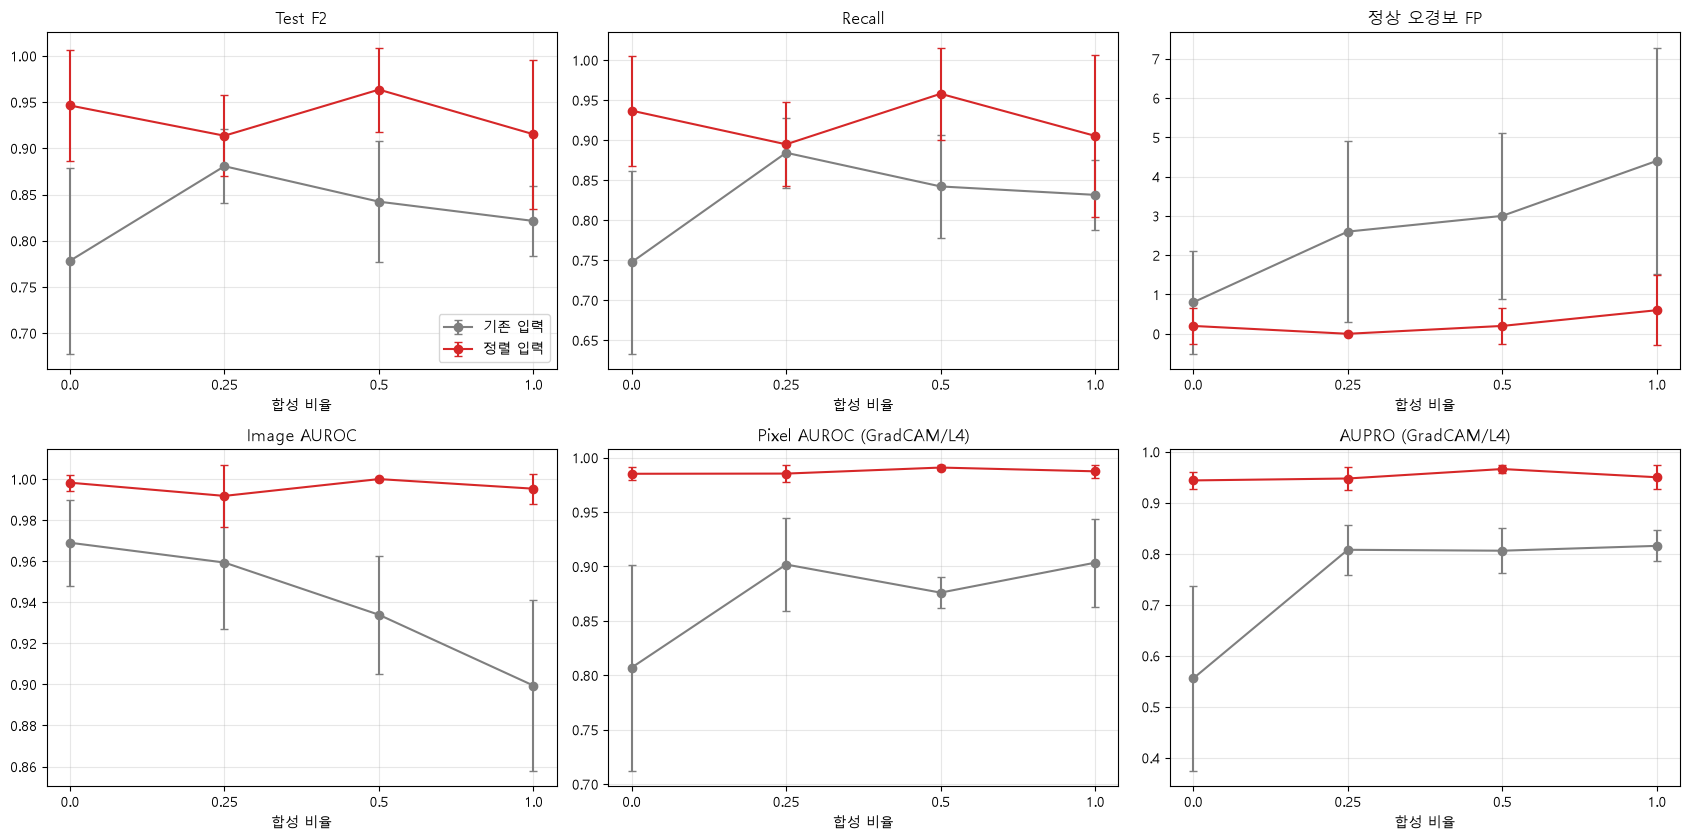

In [8]:
fig, axs = plt.subplots(2, 3, figsize=(17, 8.5))
for a, (key, label) in zip(axs.ravel(), [("f2", "Test F2"), ("recall", "Recall"), ("fp", "정상 오경보 FP"), ("img_auroc", "Image AUROC"),
                                           ("pa_GradCAM_layer4", "Pixel AUROC (GradCAM/L4)"), ("aupro_GradCAM_layer4", "AUPRO (GradCAM/L4)")]):
    for name, getter, color in [("기존 입력", base_s, "tab:gray"), ("정렬 입력", align_s, "tab:red")]:
        m = [getter(key, r).mean() for r in ratios]; s = [getter(key, r).std(ddof=1) for r in ratios]
        a.errorbar(range(len(ratios)), m, yerr=s, marker="o", capsize=3, label=name, color=color)
    a.set_xticks(range(len(ratios))); a.set_xticklabels([str(r) for r in ratios]); a.set_xlabel("합성 비율")
    a.set_title(label); a.grid(alpha=.3)
axs[0, 0].legend()
plt.tight_layout(); plt.show()

## 7. Grad-CAM — 정렬 입력 모델, 합성 비율별

같은 test 결함(유형별 첫 장, 고정 규칙)과 정상 1장을 비율별 모델로 본다. 시드 하나(`VIZ_SEED`)의 모델이며, 맵은 원본 프레임(224)에 그린다. `p` = bad 확률.

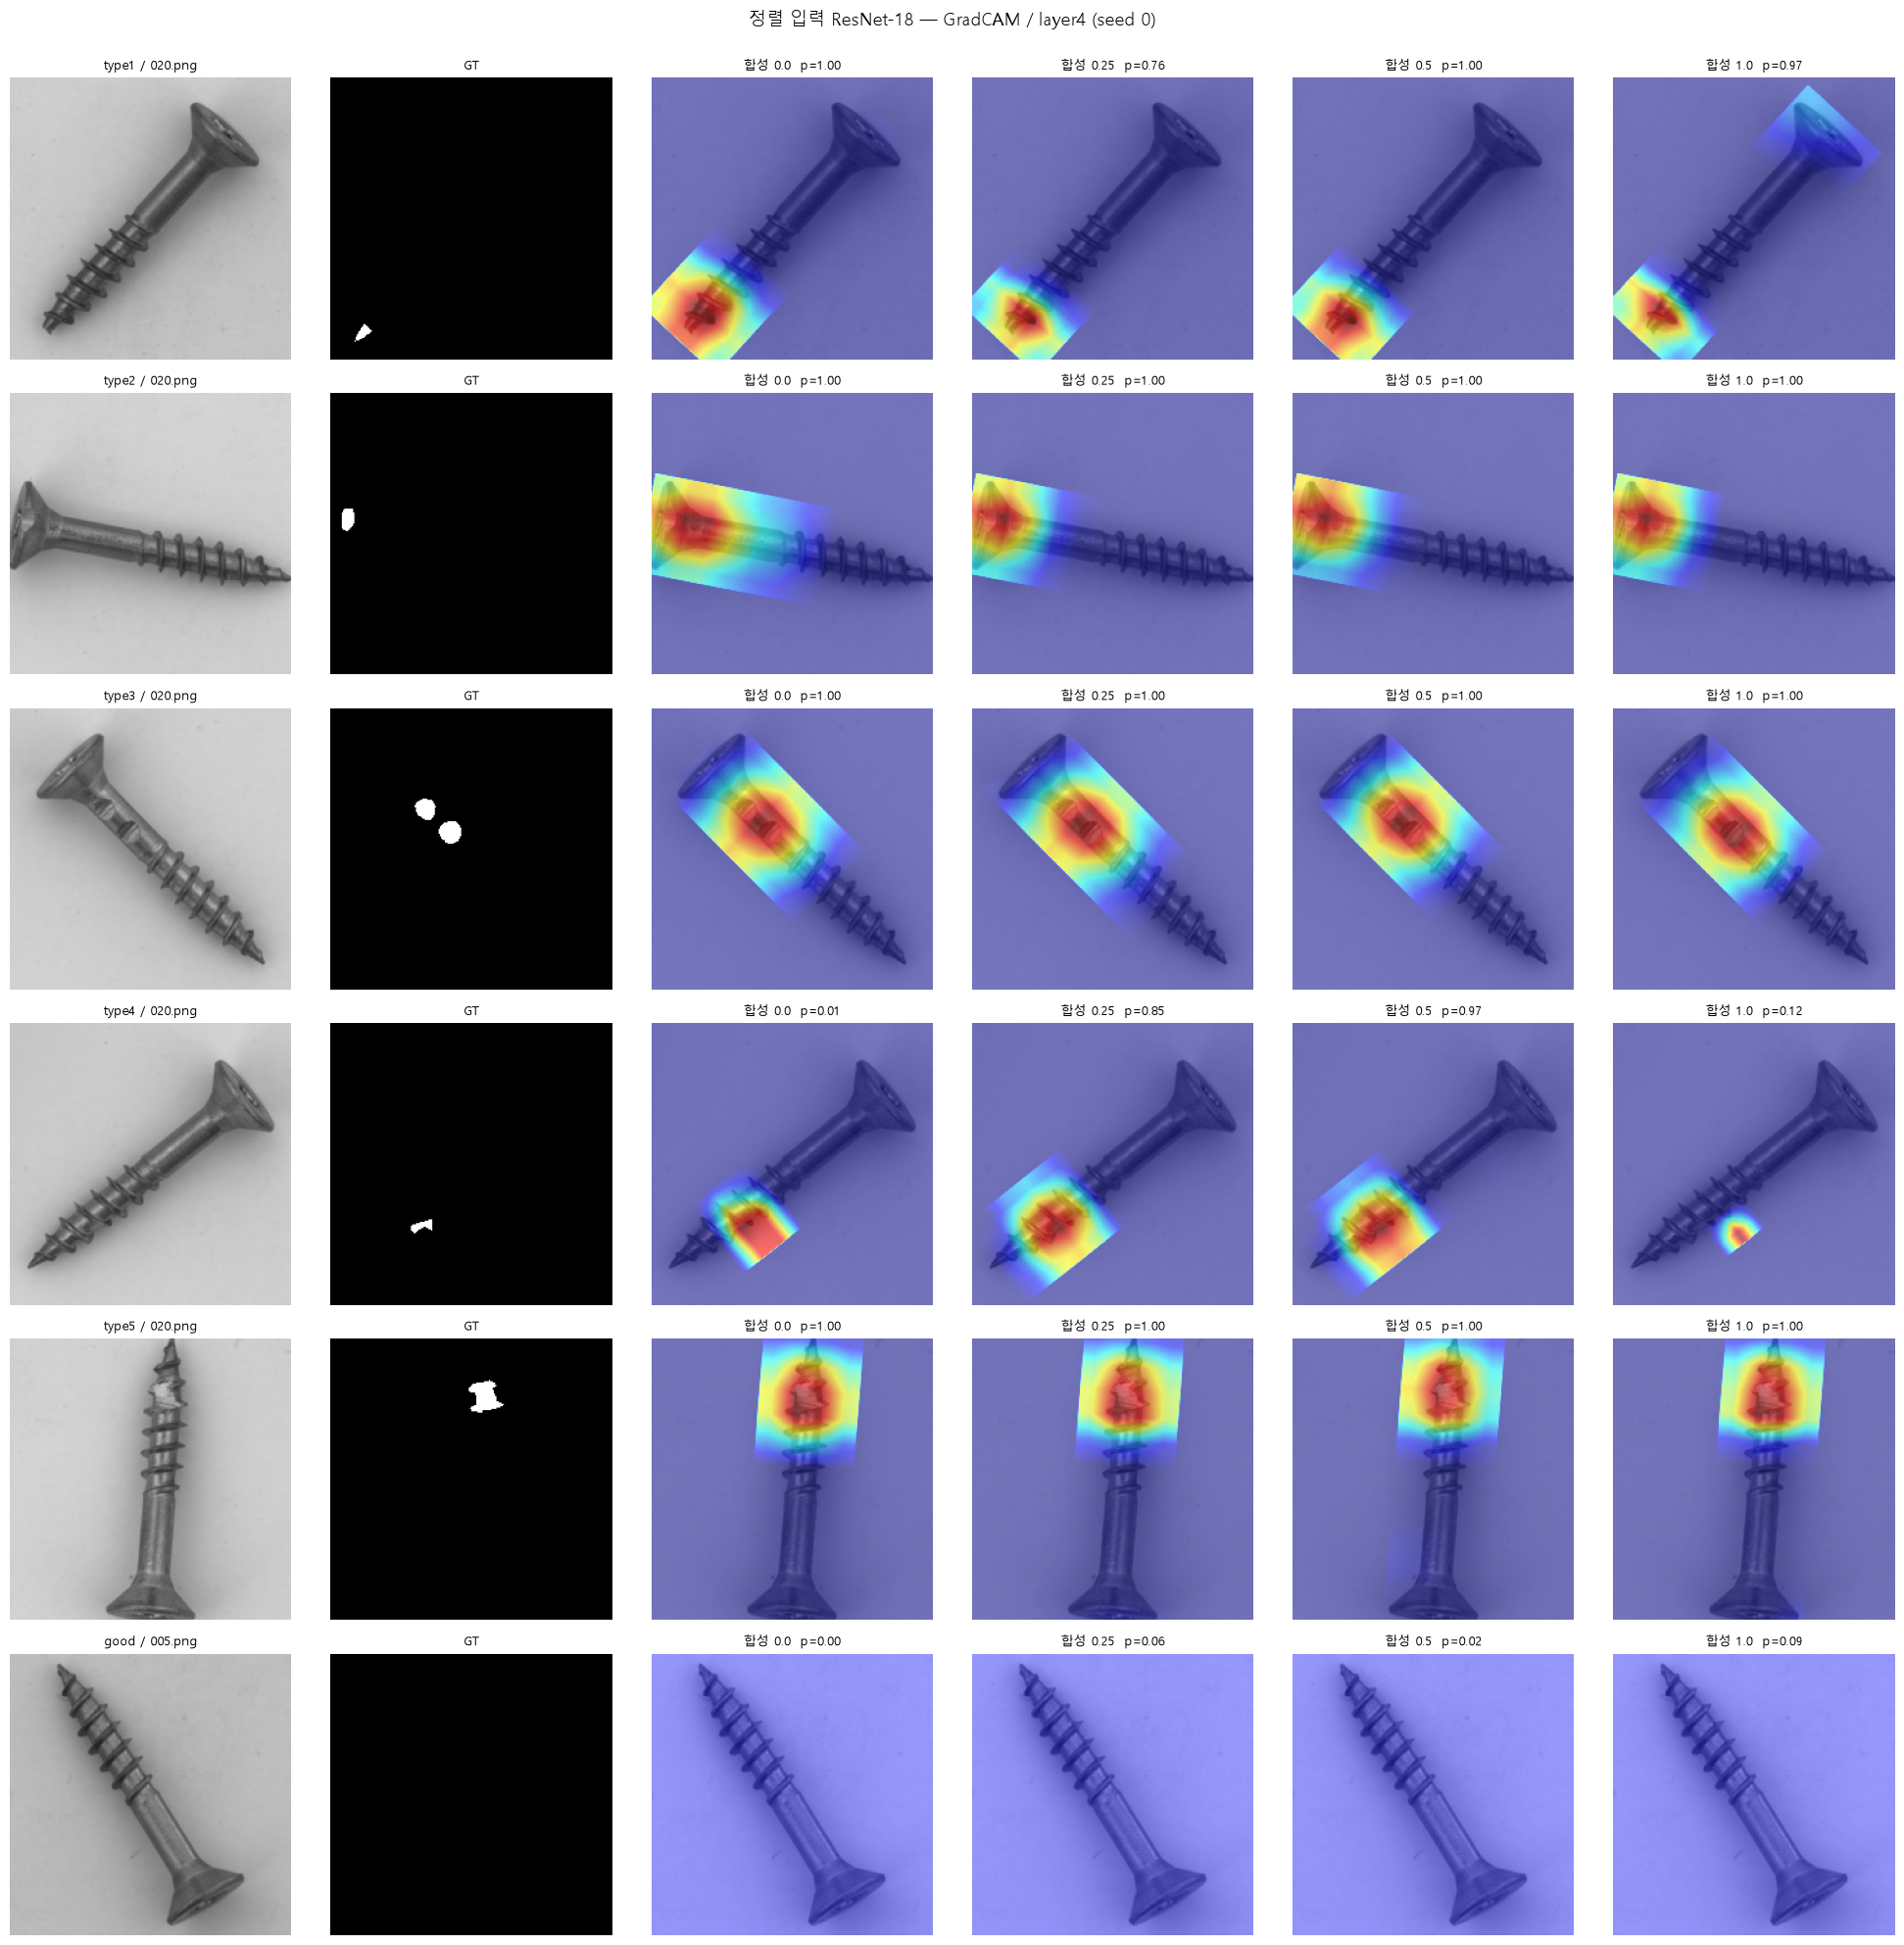

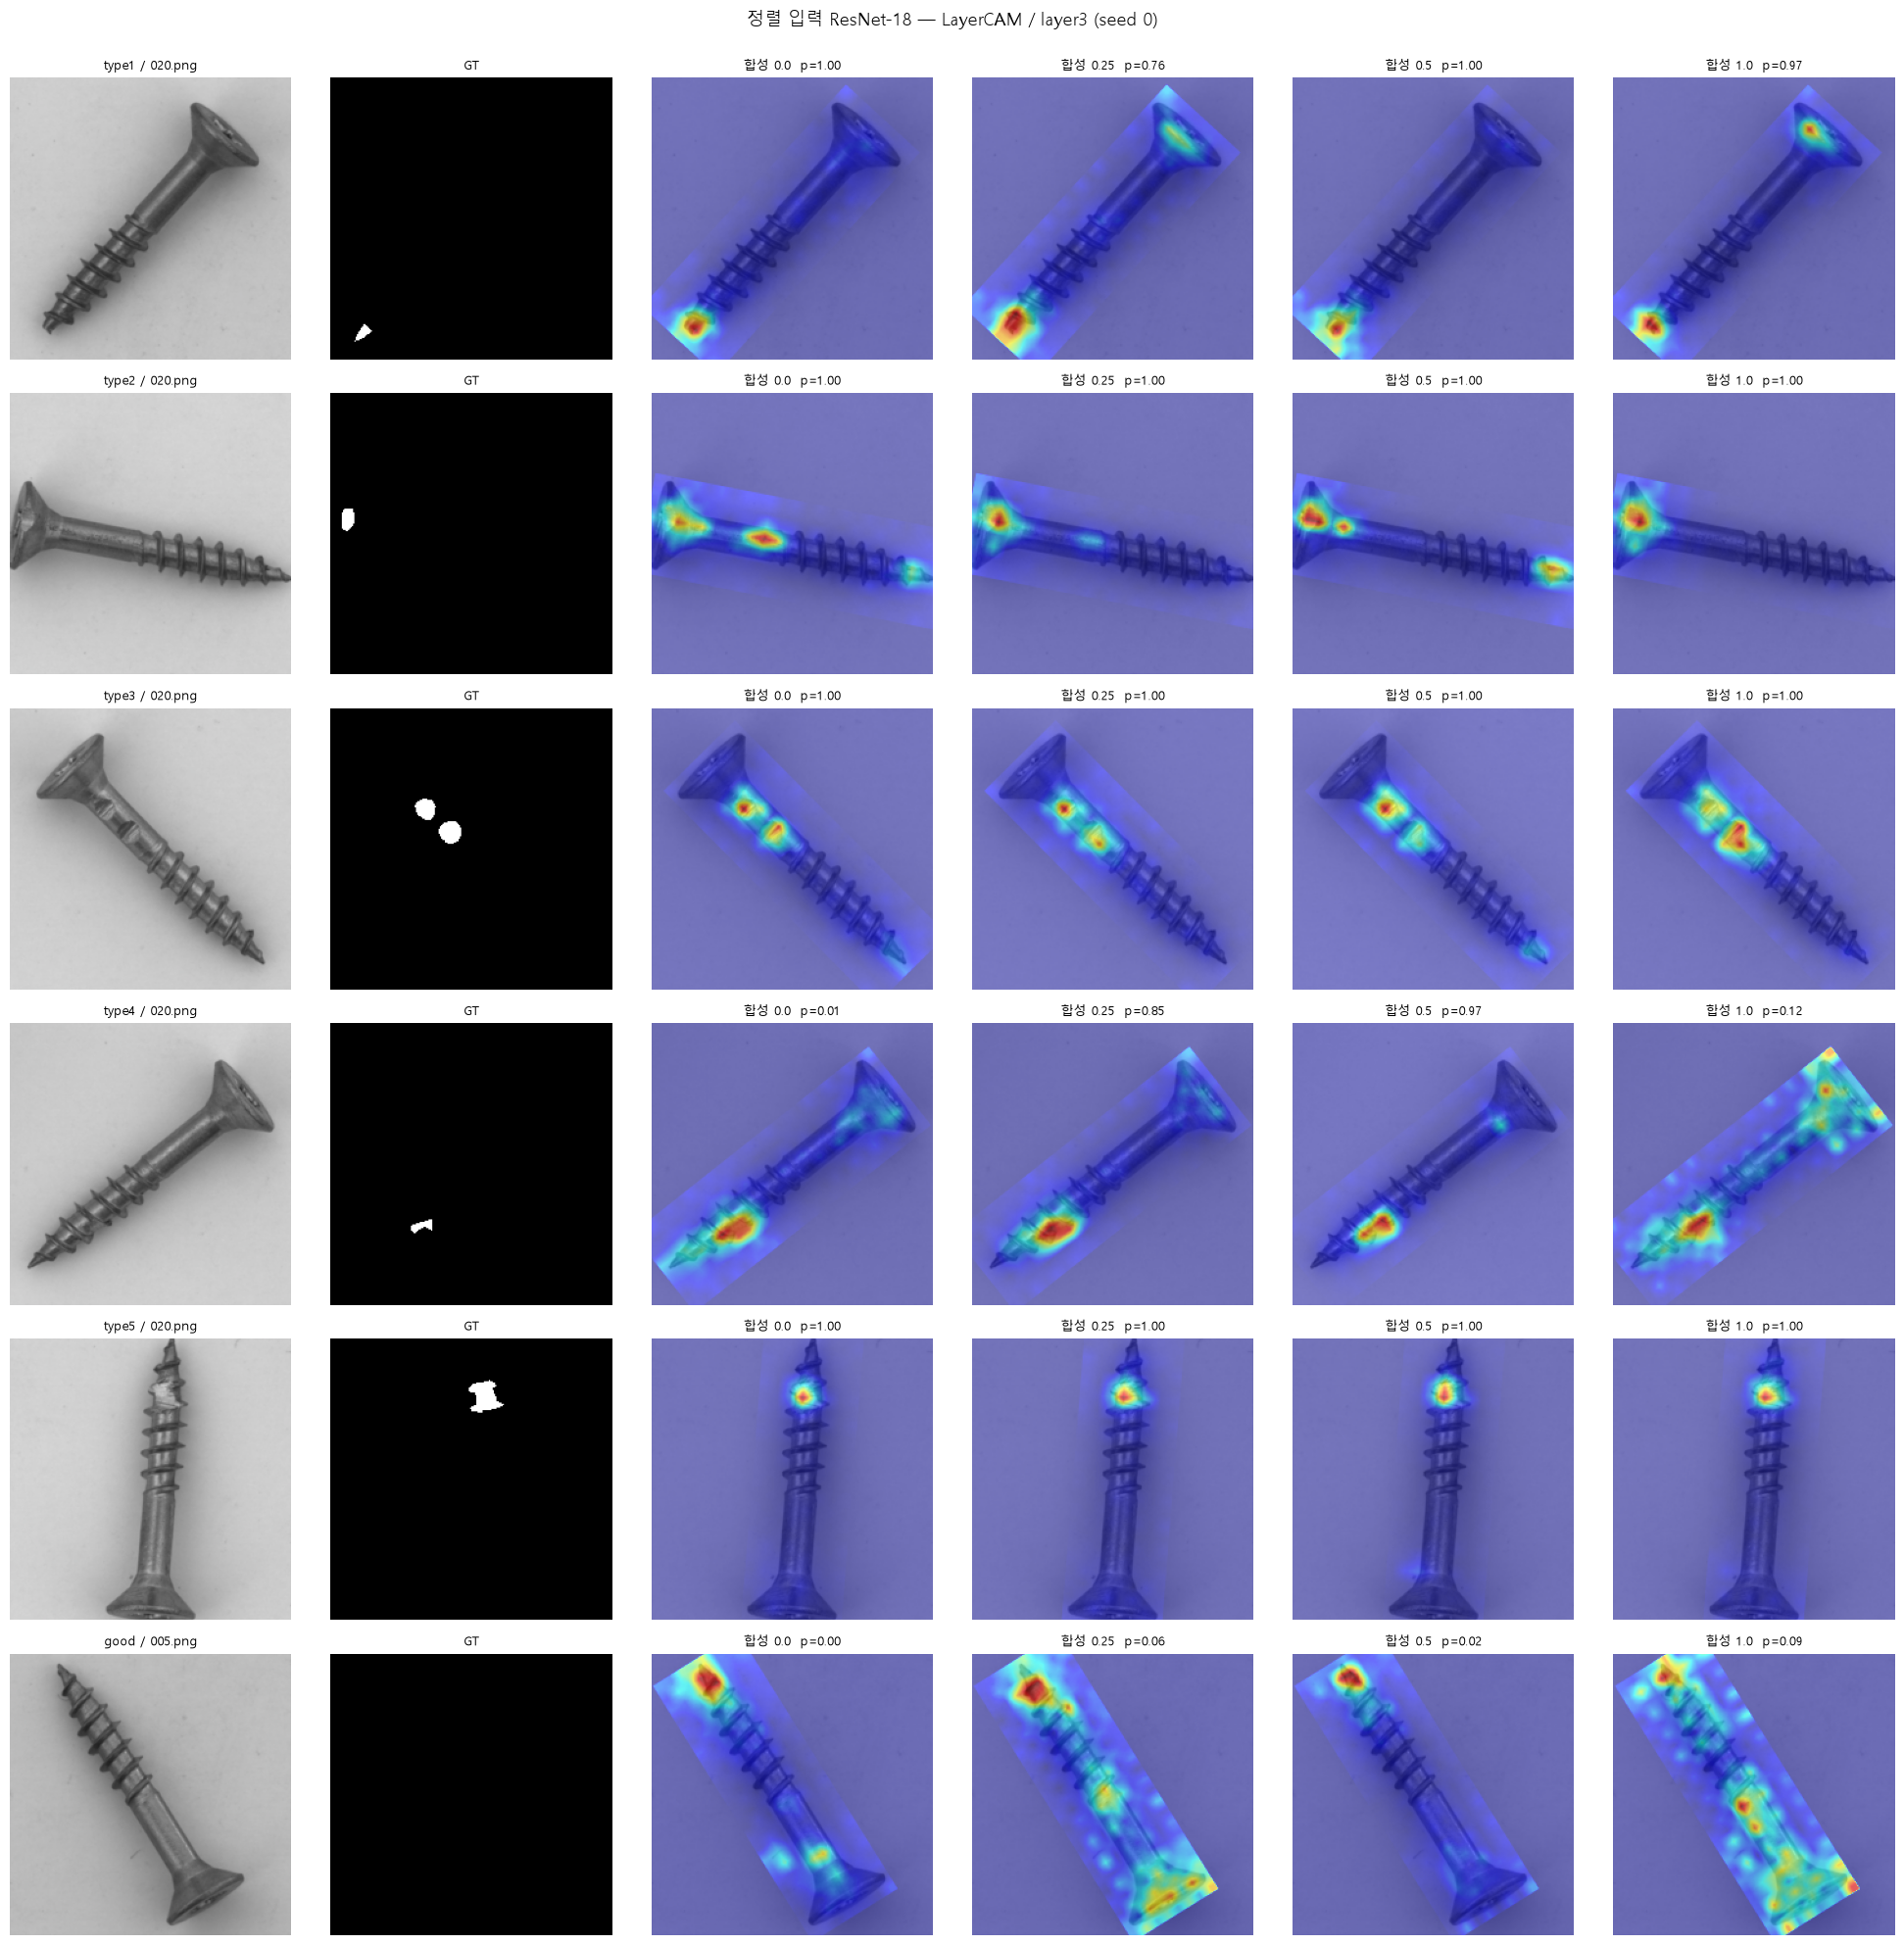

In [9]:
VIZ_SEED = seeds[0]
VIZ_RECS = [next(r for r in defects if r["type"] == t) for t in synth.TYPES] + [next(r for r in test_recs if r["type"] == "good")]
_mods = {}
def get_model(ratio):
    if ratio not in _mods:
        m = build_model_bin("resnet18").to(device)
        m.load_state_dict(torch.load(model_path(ratio, VIZ_SEED), map_location=device)); m.eval(); _mods[ratio] = m
    return _mods[ratio]

def show(method, layer):
    fig, axs = plt.subplots(len(VIZ_RECS), 2 + len(ratios), figsize=(3.3 * (2 + len(ratios)), 3.3 * len(VIZ_RECS)))
    maps = {r: cam_maps(get_model(r), method, layer, VIZ_RECS) for r in ratios}
    for i, rec in enumerate(VIZ_RECS):
        img = np.clip(inv_normalize(val_transform(Image.open(rec["path"]).convert("RGB"))).numpy().transpose(1, 2, 0), 0, 1)
        gt = load_mask(rec["mask"]) if rec["mask"] else np.zeros((224, 224), np.float32)
        axs[i, 0].imshow(img); axs[i, 0].set_title(f"{rec['type']} / {os.path.basename(rec['path'])}", fontsize=9)
        axs[i, 1].imshow(gt, cmap="gray", vmin=0, vmax=1); axs[i, 1].set_title("GT", fontsize=9)
        for j, r in enumerate(ratios):
            x = EVAL_TF(aligned_pil(rec["path"])).unsqueeze(0).to(device)
            with torch.no_grad():
                p = torch.softmax(get_model(r)(x), 1)[0, 1].item()
            axs[i, 2 + j].imshow(show_cam_on_image(img, maps[r][i], use_rgb=True)); axs[i, 2 + j].set_title(f"합성 {r}  p={p:.2f}", fontsize=9)
    for a in axs.ravel(): a.axis("off")
    fig.suptitle(f"정렬 입력 ResNet-18 — {method} / {layer} (seed {VIZ_SEED})", fontsize=13, y=1.0)
    plt.tight_layout(); plt.show()

show("GradCAM", "layer4")
show("LayerCAM", "layer3")

## 8. 해석 시 주의

- 결함 19장·시드 5개라 작은 Δ 는 효과로 보지 않는다(p 와 표준편차를 같이 본다).
- 정렬 입력에서는 val F2 가 포화(1.0)돼 "val F2 최고 epoch" 선택이 무의미해질 수 있다(선택된 epoch 행 확인). 선택 기준 변경은 baseline 과 비교 조건이 달라지므로 이 노트북에서는 하지 않았다.
- 위치 지표는 결함 19장 기준이고 정렬 프레임 CAM 을 원본 프레임으로 역투영해 계산했다.